Un sistem de clasificare a e-mail-urilor foloses,te o ret,ea bayesiană pentru a evalua probabilitatea ca un e-mail să fie
spam (S) în funct,ie de anumite caracteristici observate. Ret,eaua include următoarele variabile:
- S: E-mail-ul poate fi spam (S = 1) sau non-spam (S = 0).
- O: E-mail-ul poate cont,ine cuvântul "ofertă" (O = 1) sau nu (O = 0).
- L: E-mail-ul poate cont,ine link-uri (L = 1) sau nu (L = 0).
- M: E-mail-ul poate avea o lungime mare (M = 1) sau nu (M = 0).
Structura Ret, elei Bayesiene

- Spam (S) influent,ează probabilitatea ca e-mail-ul să cont,ină cuvântul "ofertă" (O) s,i să cont,ină link-uri (L).
- Lungimea e-mail-ului (M) este influent,ată atât de faptul că este spam (S) cât s,i de prezent,a link-urilor (L).

Tabele de probabilităt, i

- P(S = 1) = 0.4, P(S = 0) = 0.6
- P(O = 1∣S = 1) = 0.7, P(O = 1∣S = 0) = 0.1
- P(L = 1∣S = 1) = 0.8, P(L = 1∣S = 0) = 0.3
- P(M = 1∣S = 1, L = 1) = 0.9, P(M = 1∣S = 1, L = 0) = 0.5
- P(M = 1∣S = 0, L = 1) = 0.6, P(M = 1∣S = 0, L = 0) = 0.2
Cerint, e

a) Identificat,i independent,ele din ret,ea.
b) Determinat,i cum clasifică ret,eaua bayesiană e-mail-urile în funct,ie de atributele O, L s,i M.

a) 
- $O \perp L | S$
- $O \perp M | S$
- $O \perp M | L,S$

b) $P(S|O,L,M)=\frac{P(S,O,L,M)}{P(O,L,M)}$

$P(O,L,M,S)=P(S) \cdot P(O|\lnot S)\cdot P(L|S) \cdot P(M|L,S)$

$P(O,L,M, \lnot S)=P(\lnot S) \cdot P(O|\lnot S)\cdot P(L|\lnot S) \cdot P(M|L,\lnot S)$

$P(O,L,M)=P(O,L,M,S)+P(O,L,M,\lnot S)$

Deci, $P(S|O,L,M)=\frac{P(S,O,L,M)}{P(O,L,M,S)+P(O,L,M,\lnot S)}$.

În cazul în care una sau mai multe variabile dintre $O, L, M$ sunt negate în $P(S|O,L,M)$, aceastea vor rămâne negate și în partea din dreapta a egalității.

In [ ]:
ps = [0.6, 0.4]
po_if_s = [
    [0.9,0.3],
    [0.1,0.7]
]
pl_if_s = [
    [0.7,0.2],
    [0.3,0.8]
] 
pm_if_s_and_l = [
    [[0.8,0.4],[0.5,0.1]],
    [[0.2,0.6],[0.5,0.9]]
]
def main():
    for O in (False, True):
        for L in (False, True):
            for M in (False, True):
                p_olms = ps[1] * po_if_s[O][1] * pl_if_s[L][1] * pm_if_s_and_l[M][1][L]
                p_olmnots = ps[0] * po_if_s[O][0] * pl_if_s[L][0] * pm_if_s_and_l[M][0][L]
                p_s_if_olm = p_olms/(p_olms+p_olmnots)
                print(f"P(S|{O=}, {L=}, {M=})={p_s_if_olm}")

main()

P(S|O=False, L=False, M=False)=0.03816793893129771
P(S|O=False, L=False, M=True)=0.13698630136986303
P(S|O=False, L=True, M=False)=0.12903225806451613
P(S|O=False, L=True, M=True)=0.4705882352941177
P(S|O=True, L=False, M=False)=0.45454545454545453
P(S|O=True, L=False, M=True)=0.7692307692307693
P(S|O=True, L=True, M=False)=0.7567567567567567
P(S|O=True, L=True, M=True)=0.9491525423728814


P(S|O=False, L=False, M=False)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.9618 |
+------+----------+
| S(1) |   0.0382 |
+------+----------+
P(S|O=False, L=False, M=True)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.8630 |
+------+----------+
| S(1) |   0.1370 |
+------+----------+
P(S|O=False, L=True, M=False)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.8710 |
+------+----------+
| S(1) |   0.1290 |
+------+----------+
P(S|O=False, L=True, M=True)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.5294 |
+------+----------+
| S(1) |   0.4706 |
+------+----------+
P(S|O=True, L=False, M=False)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.5455 |
+------+----------+
| S(1) |   0.4545 |
+------+----------+
P(S|O=True, L=False, M=True)=+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.2308 |
+------+----------+
| S(1) |   0.7692 |
+

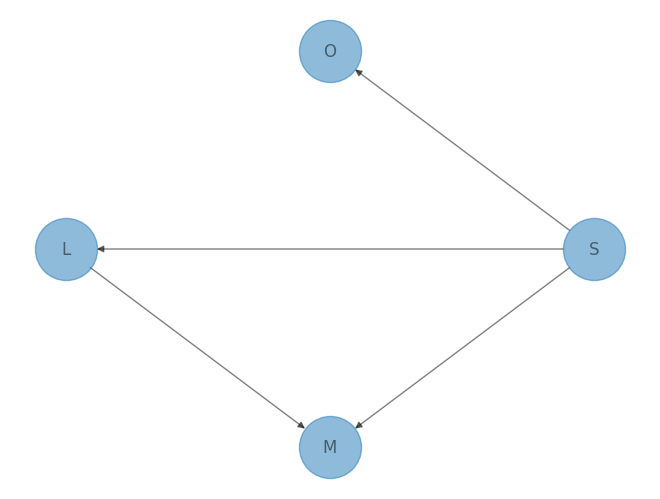

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
def bayes_network():
    email_model = DiscreteBayesianNetwork([('S', 'O'), ('S', 'L'), ('S', 'M'), ('L', 'M')])
    pos = nx.circular_layout(email_model)
    nx.draw(email_model, with_labels=True, pos=pos, alpha=0.5, node_size=2000)

    CPD_S = TabularCPD(variable='S', variable_card=2, values=[[0.6], [0.4]])

    CPD_O = TabularCPD(variable='O', variable_card=2, values=[
        [0.9,0.3],
        [0.1,0.7]],
        evidence=['S'],
        evidence_card=[2]
    )
    CPD_L = TabularCPD(variable='L', variable_card=2, values=[
        [0.7,0.2],
        [0.3,0.8]],
        evidence=['S'],
        evidence_card=[2]
    )
    CPD_M = TabularCPD(variable='M', variable_card=2, values=[
        [0.8,0.4,0.5,0.1],
        [0.2,0.6,0.5,0.9]],
        evidence = ['S', 'L'],
        evidence_card = [2, 2]
    )

    email_model.add_cpds(CPD_S, CPD_O, CPD_L, CPD_M)
    # email_model.get_cpds()

    for O in (False, True):
        for L in (False, True):
            for M in (False, True):
                infer = VariableElimination(email_model)
                posterior_p = infer.query(["S"], evidence={"O": O, "L": L, "M": M})
                print(f"P(S|{O=}, {L=}, {M=})={posterior_p}")
bayes_network()


Prin urmare, un mail este mai probabil spam dacă:

- $O, \lnot L, M$
- $O, L, \lnot M$
- $O, L, M$

În celelalte cazuri, este mai probabil ca mail-ul să nu fie spam.